In [30]:
# Imports iniciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MaxAbsScaler, MinMaxScaler, Normalizer, RobustScaler

# Modelos
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import ElasticNet

# Se quiser usar XGBoost / LightGBM
from xgboost import XGBRegressor

# XGBoost com n_jobs=-1 fica ~30x mais lento nesta máquina (threads disputando os núcleos).
# Com 8 threads, 300 árvores treinam em < 1 s.
N_JOBS_XGB = 8

In [31]:
# Dados tratados (01) + POIs (03) + features (05)
df = pd.read_parquet("/home/felipe/Projeto/Portfolio/Portfolio2/Regression_PriceHouse/data/interim/aluguel_sp_features.parquet")
df.shape

(22213, 193)

In [32]:
#criação dos score. Mesma fórmula do projeto de compra, aplicada aos POIs do aluguel (notebook 03).

df['score_escola_privada'] = (
    1.2 * np.exp(-df['dist_escola_privada'] / 600) +
    0.6 * df['qtd_escola_privada_500m']
)

df['score_escola_publica'] = (
    0.6 * np.exp(-df['dist_escola_publica'] / 600) +
    0.2 * df['qtd_escola_publica_500m']
)


df['score_hospitais'] = (
    0.8 * np.exp(-df['dist_hospital'] / 1200) +
    0.4 * df['qtd_hospital_1km']
)


df['score_mercado'] = (
    1.0 * np.exp(-df['dist_supermercado'] / 400) +
    0.4 * df['qtd_supermercado_500m']
)


# contagem em 300 m não existe na base do aluguel -> usa 500 m
df['score_farmacia'] = (
    0.6 * np.exp(-df['dist_farmacia'] / 300) +
    0.2 * df['qtd_farmacia_500m']
)


df['score_parque'] = (
    1.2 * np.exp(-df['dist_parque'] / 1200) +
    0.8 * df['qtd_parque_1km']
)


df['score_seguranca'] = (
    1.0 * np.exp(-df['dist_policia'] / 1500) +
    0.3 * df['qtd_policia_500m']
)

df['score_educacao'] = (
    df['score_escola_privada']
    - 0.2 * df['score_escola_publica']
)

# novo no aluguel: metrô foi o único POI com efeito próprio na inferência (notebook 04)
df['score_metro'] = (
    1.0 * np.exp(-df['dist_metro'] / 800) +
    0.3 * df['qtd_metro_1km']
)


#Criando a coluna faixa_area
area = df['area']

bins = [0, 50, 80, 120, 200, 400, area.max()]
labels = ['Até 50', '50–80', '80–120', '120–200', '200–400', '400+']

df['faixa_area'] = pd.cut(area, bins=bins, labels=labels)

df['faixa_area'].value_counts(normalize=True).sort_index()

faixa_area
Até 50    0.5232
50–80     0.1900
80–120    0.0852
120–200   0.0900
200–400   0.0851
400+      0.0266
Name: proportion, dtype: float64

> A célula `nota` do ML3 (preço normalizado + ruído) **não foi trazida**: ela é calculada a partir do próprio preço, então entregaria o alvo ao modelo.

In [33]:
# No aluguel o tipo já vem padronizado pelo QuintoAndar
mapa_tipo = {
    "Apartamento": "apartamento",
    "StudioOuKitchenette": "studio",
    "Casa": "casa",
    "CasaCondominio": "casa_condominio",
}

df["tipo_imovel_cat"] = df["type"].map(mapa_tipo)

In [34]:
df["is_studio"] = (df["type"] == "StudioOuKitchenette").astype(int)
df["is_condominio"] = (df["type"] == "CasaCondominio").astype(int)

In [35]:
#ajustando o dataframe para valores e formatos corretos.
pd.options.display.float_format = '{:.4f}'.format

#Antes de iniciar, vamos transformar o aluguel em log
df['log_rent'] = np.log(df['rent'].clip(lower=1))

In [36]:
df["tipo_imovel_cat"].value_counts()

tipo_imovel_cat
apartamento        13508
casa                5012
studio              3340
casa_condominio      353
Name: count, dtype: int64

In [37]:
df

,id,type,area,bathrooms,bedrooms,suites,parkingSpaces,rent,iptuPlusCondominium,address,...,score_mercado,score_farmacia,score_parque,score_seguranca,score_educacao,score_metro,faixa_area,tipo_imovel_cat,is_studio,is_condominio
0,895407132,Casa,80.0000,1,2,0,1,1500,0.0000,Rua Arnaldo Estrella,...,0.0715,0.0086,1.3346,0.4795,0.0273,0.0000,50–80,casa,0,0
1,895598034,Casa,50.0000,1,1,0,0,1300,0.0000,Rua Condé da Redinha,...,0.1171,0.0000,0.3486,0.4541,0.0929,0.0000,Até 50,casa,0,0
2,895521778,Casa,45.0000,1,2,0,0,950,9.0000,Rua Esther Lang,...,0.8829,0.0000,0.4164,0.3068,0.2558,0.0000,Até 50,casa,0,0
3,895270262,Casa,250.0000,4,3,3,2,3580,0.0000,Rua Antônio Tirabassi,...,0.7093,0.0000,0.4965,0.3030,1.2535,0.0000,200–400,casa,0,0
4,895521782,Apartamento,45.0000,1,1,0,0,950,9.0000,Rua Esther Lang,...,0.8829,0.0000,0.4164,0.3068,0.2558,0.0000,Até 50,apartamento,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22208,895341207,CasaCondominio,450.0000,5,3,3,3,4700,1100.0000,Rua Natal,...,0.0762,0.0139,2.2812,0.5369,0.4562,0.0000,400+,casa_condominio,0,1
22209,895307842,Casa,60.0000,2,2,0,4,3250,113.0000,Rua Alamar,...,0.0723,0.0130,2.3090,0.5618,0.4375,0.0000,50–80,casa,0,0
22210,895280994,Casa,301.0000,2,3,2,3,3560,0.0000,Rua Canhoba,...,0.1283,0.0306,2.6983,0.6475,0.2727,0.0000,200–400,casa,0,0
22211,895307848,Casa,40.0000,1,1,0,4,2250,113.0000,Rua Alamar,...,0.0723,0.0130,2.3090,0.5618,0.4375,0.0000,Até 50,casa,0,0


### DEFINIÇÃO DAS COLUNAS

In [38]:
num_features = [
    'bedrooms', 'bathrooms', 'parkingSpaces', 'area', 'suites',
    'score_escola_privada', 'score_escola_publica',
    'score_hospitais', 'score_mercado',
    'score_farmacia', 'score_parque', 'score_seguranca', 'score_metro',
    # atributos com efeito controlado no notebook 02
    'mobiliado', 'am_ar_condicionado', 'inst_piscina', 'inst_academia', 'am_varanda',
    # localização (notebook 05)
    'dist_centro_km', 'dist_polo_km'
]

#cat_features = ['bairro', 'faixa_area']
# regionName fora: em produção a localização vem só do geocoding (lat/lon -> POIs), igual ao projeto de compra
cat_features = ['tipo_imovel_cat']
target = 'log_rent'

In [39]:
from sklearn.model_selection import train_test_split

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [40]:
X_train

,bedrooms,bathrooms,parkingSpaces,area,suites,score_escola_privada,score_escola_publica,score_hospitais,score_mercado,score_farmacia,...,score_seguranca,score_metro,mobiliado,am_ar_condicionado,inst_piscina,inst_academia,am_varanda,dist_centro_km,dist_polo_km,tipo_imovel_cat
18791,2,1,1,43.0000,0,2.5390,0.7180,0.2827,0.8716,0.5921,...,1.0201,0.1299,0,0,0,0,0,5.7431,7.9958,apartamento
12292,1,1,0,36.0000,0,0.4191,0.1419,2.0418,2.2218,2.4127,...,0.6941,2.2327,0,0,0,0,0,0.4195,2.2298,studio
5416,3,2,2,91.0000,1,1.9835,0.8873,0.2842,1.7561,1.0430,...,0.5457,0.1761,0,1,1,1,1,10.2459,4.9734,apartamento
6974,1,1,0,17.0000,0,0.4979,0.0255,0.7530,0.2624,0.0382,...,1.0579,0.1492,0,0,0,1,0,8.4926,0.5669,studio
10733,1,1,1,43.0000,0,0.3629,0.2215,0.7601,1.0316,0.4104,...,0.5941,0.6811,0,1,1,1,1,6.4386,4.6851,apartamento
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11964,4,3,2,185.0000,0,2.2214,0.1761,1.8119,3.1458,2.6784,...,1.1145,1.1039,0,0,0,0,0,5.7460,2.4147,casa
21575,2,1,1,50.0000,0,1.3162,0.2558,0.2440,2.1346,0.8796,...,0.5932,1.5002,0,0,0,0,1,7.4363,9.5799,apartamento
5390,2,2,1,68.0000,0,0.3024,0.4999,0.9944,2.0509,0.6250,...,0.4188,0.6670,0,0,1,1,0,11.5706,5.1387,apartamento
860,3,2,2,89.0000,1,2.5734,0.2211,0.1580,0.8593,0.0807,...,0.6657,0.0263,0,0,1,1,1,11.8695,5.2550,apartamento


## 🛠️ Criando um Outlier Capper simples (quantis)

### Scikit-learn não tem nativo, então criamos um transformer:

In [41]:
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np
import pandas as pd

class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.q_low_ = X.quantile(self.lower)
        self.q_high_ = X.quantile(self.upper)
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.clip(self.q_low_, self.q_high_, axis=1)

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler

In [43]:
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('outliers', QuantileClipper(0.01, 0.99)),
    ('scaler', StandardScaler())  # depois vamos trocar
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features)
    ]
)

In [44]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [45]:
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.001),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5),

    'RandomForest': RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'GradientBoosting': GradientBoostingRegressor(random_state=42),

    'XGBoost': XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=N_JOBS_XGB
    ),
    'DecisionTree': DecisionTreeRegressor(random_state=42)
}

scalers = {
    'None': None,
    'MaxAbsScaler': MaxAbsScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'Normalizer': Normalizer(),
    'RobustScaler': RobustScaler(),
    'StandardScaler': StandardScaler()
}

In [46]:
%%time

results = []

# Depois, no loop, use esta abordagem
for model_name, model in models.items():
    for scaler_name, scaler in scalers.items():

        # Criar um novo pipeline numérico com o scaler atual
        num_pipeline = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('outliers', QuantileClipper(0.01, 0.99)),
            ('scaler', scaler if scaler is not None else 'passthrough')
        ])

        # Criar um novo preprocessor
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_pipeline, num_features),
                ('cat', cat_pipeline, cat_features)  # cat_pipeline já definido
            ]
        )

        pipe = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('model', model)
        ])

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        mape = mean_absolute_percentage_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)

        results.append({
            'Model': model_name,
            'Scaler': scaler_name,
            'R2': r2,
            'RMSE': rmse,
            'MAE': mae,
            'MAPE': mape
        })

CPU times: user 5min 56s, sys: 21.4 s, total: 6min 17s
Wall time: 1min 1s


In [47]:
results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by=['R2', 'RMSE'],
    ascending=[False, True]
).reset_index(drop=True))

               Model          Scaler     R2   RMSE    MAE   MAPE
0            XGBoost            None 0.8686 0.2538 0.1883 0.0231
1            XGBoost    MaxAbsScaler 0.8686 0.2538 0.1883 0.0231
2            XGBoost    MinMaxScaler 0.8686 0.2538 0.1883 0.0231
3            XGBoost    RobustScaler 0.8686 0.2538 0.1883 0.0231
4            XGBoost  StandardScaler 0.8682 0.2541 0.1884 0.0231
5       RandomForest            None 0.8593 0.2625 0.1935 0.0237
6       RandomForest    RobustScaler 0.8592 0.2626 0.1935 0.0237
7       RandomForest  StandardScaler 0.8591 0.2628 0.1936 0.0238
8       RandomForest    MaxAbsScaler 0.8590 0.2628 0.1936 0.0237
9       RandomForest    MinMaxScaler 0.8590 0.2628 0.1936 0.0238
10           XGBoost      Normalizer 0.8562 0.2654 0.1978 0.0243
11      RandomForest      Normalizer 0.8496 0.2715 0.2014 0.0247
12  GradientBoosting    RobustScaler 0.8444 0.2761 0.2086 0.0256
13  GradientBoosting            None 0.8444 0.2761 0.2086 0.0256
14  GradientBoosting    M

## Criando o gráfico de Shap para interpretação do modelo

In [48]:
import shap
import matplotlib.pyplot as plt

# Pipeline numérico final
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('outliers', QuantileClipper(0.01, 0.99)),
    ('scaler', StandardScaler())
])

# Pipeline categórico
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False))
])

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features)
    ]
)

# Modelo final
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=N_JOBS_XGB
)

pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb_model)
])

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

## 2️⃣ Extrair dados transformados + nomes das features

### ⚠️ Passo crítico: SHAP não entende Pipeline, só o modelo + matriz final.

In [49]:
# Dados transformados
X_train_transformed = pipe.named_steps['preprocessor'].transform(X_train)

# Nomes das features após o OneHot
num_feature_names = num_features

cat_feature_names = (
    pipe.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['encoder']
    .get_feature_names_out(cat_features)
)

feature_names = list(num_feature_names) + list(cat_feature_names)

In [50]:
feature_names

['bedrooms',
 'bathrooms',
 'parkingSpaces',
 'area',
 'suites',
 'score_escola_privada',
 'score_escola_publica',
 'score_hospitais',
 'score_mercado',
 'score_farmacia',
 'score_parque',
 'score_seguranca',
 'score_metro',
 'mobiliado',
 'am_ar_condicionado',
 'inst_piscina',
 'inst_academia',
 'am_varanda',
 'dist_centro_km',
 'dist_polo_km',
 'tipo_imovel_cat_apartamento',
 'tipo_imovel_cat_casa',
 'tipo_imovel_cat_casa_condominio',
 'tipo_imovel_cat_studio']

In [51]:
explainer = shap.Explainer(
    pipe.named_steps['model'],
    X_train_transformed,
    feature_names=feature_names
)

shap_values = explainer(X_train_transformed)

 99%|===================| 17664/17770 [02:25<00:00]        

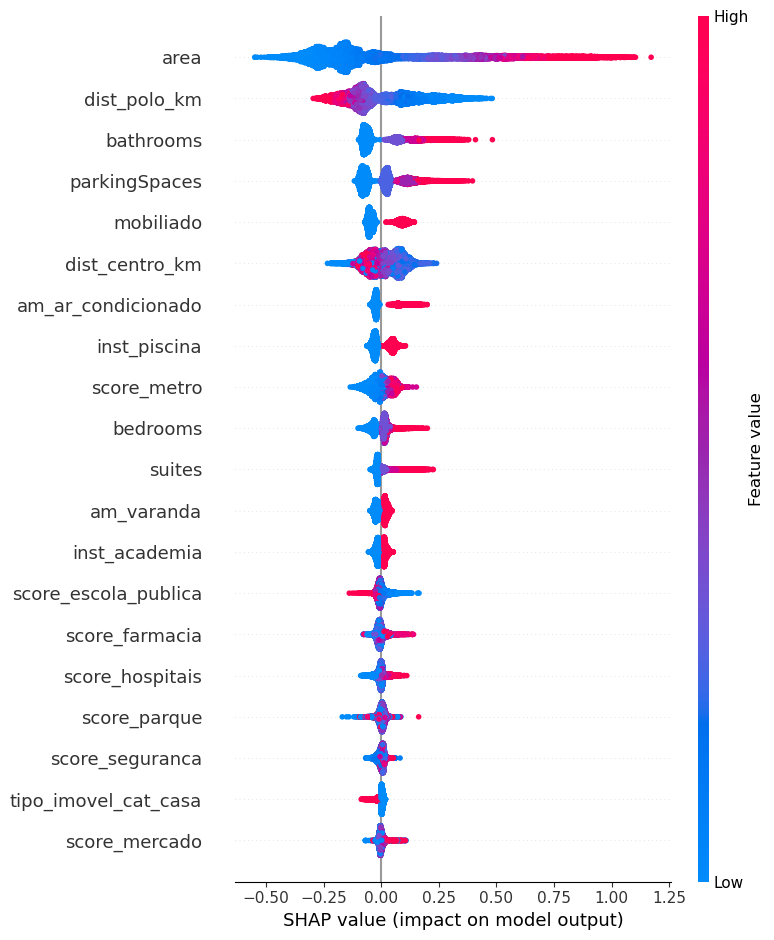

In [52]:
shap.summary_plot(
    shap_values,
    X_train_transformed,
    feature_names=feature_names,
    show=True
)

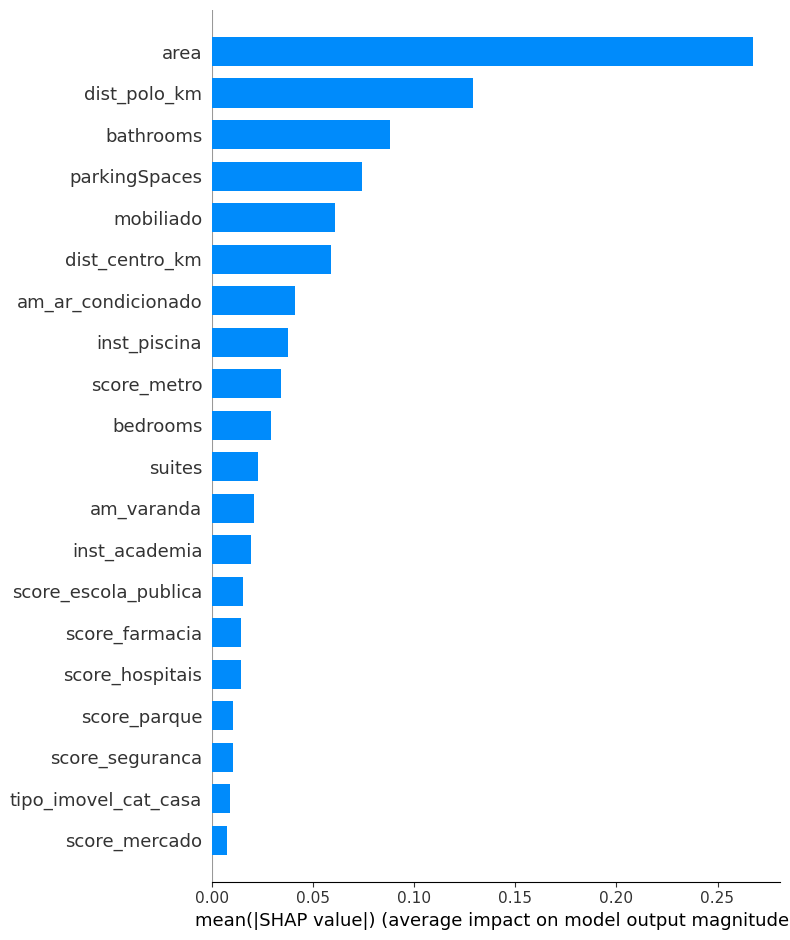

In [53]:
shap.summary_plot(
    shap_values,
    X_train_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

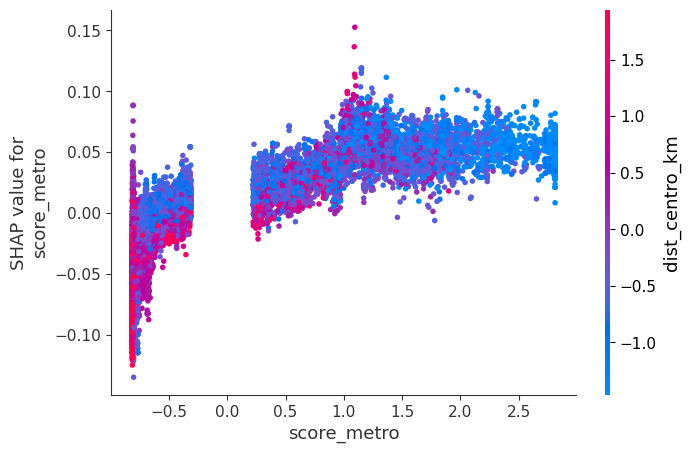

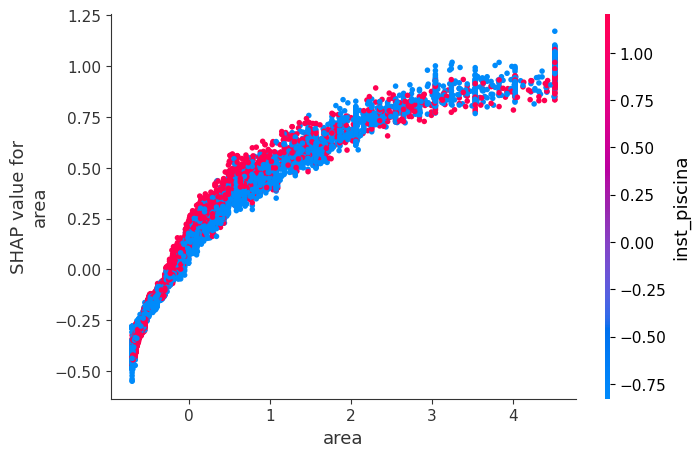

In [54]:
shap.dependence_plot(
    "score_metro",
    shap_values.values,
    X_train_transformed,
    feature_names=feature_names
)

shap.dependence_plot(
    "area",
    shap_values.values,
    X_train_transformed,
    feature_names=feature_names
)

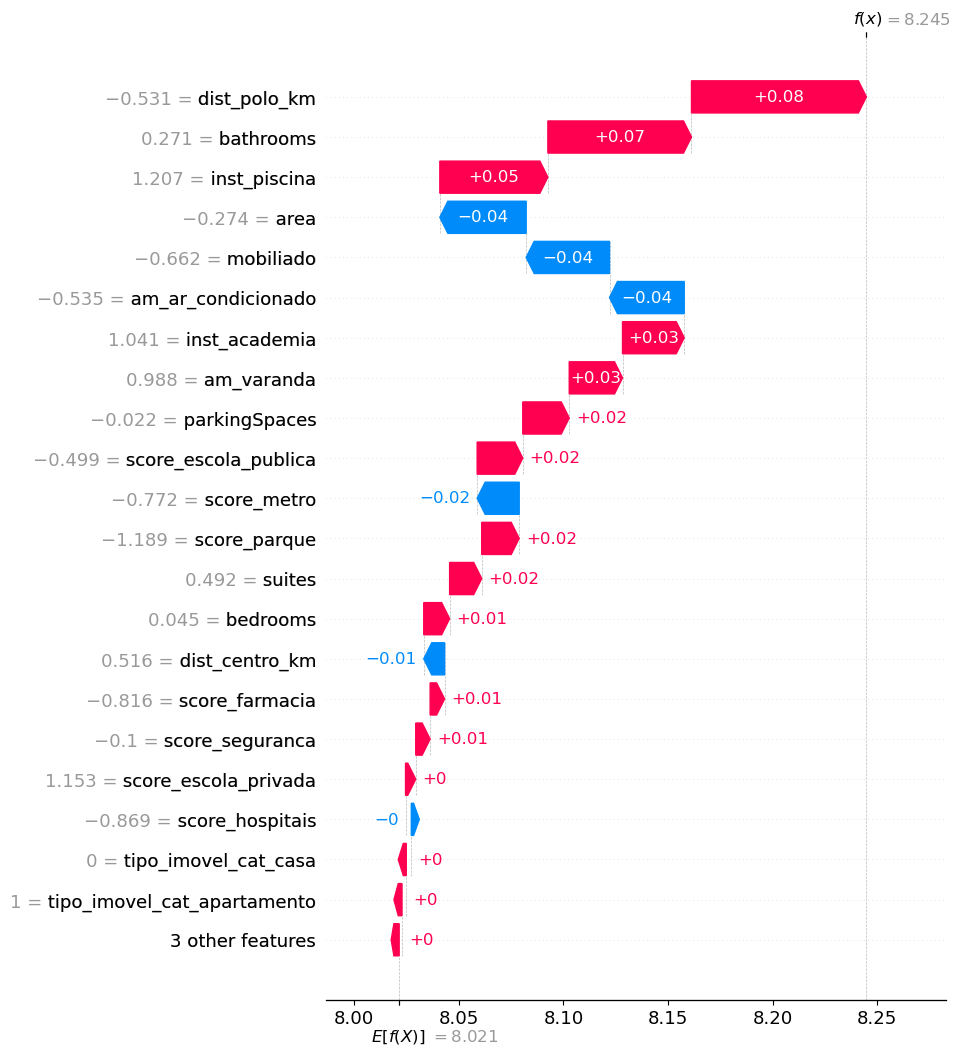

In [56]:
idx = 10  # qualquer índice

shap.plots.waterfall(
    shap_values[idx],
    max_display=22
)

In [57]:
import numpy as np

# valor base do SHAP (média da previsão em log) convertido para R$
beta_0 = shap_values.base_values[0]
aluguel_base = np.exp(beta_0)

aluguel_base

3045.5262054196724

# 🧠 Conclusão dos Resultados — SHAP Values

_(preenchido após execução)_

## 🔧 Exemplo de Estrutura com Optuna (XGBoost)

In [58]:
import optuna
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import numpy as np

def objective(trial):

    model = XGBRegressor(
        n_estimators=trial.suggest_int('n_estimators', 200, 800),
        max_depth=trial.suggest_int('max_depth', 3, 10),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
        reg_alpha=trial.suggest_float('reg_alpha', 0.0, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 0.0, 1.0),
        random_state=42,
        n_jobs=N_JOBS_XGB
    )

    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    return rmse

In [59]:
%%time

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=250)

print("Best RMSE:", study.best_value)
print("Best params:", study.best_params)

Best RMSE: 0.24656850734942448
Best params: {'n_estimators': 761, 'max_depth': 8, 'learning_rate': 0.027938309420457365, 'subsample': 0.6405771460018366, 'colsample_bytree': 0.6181897514349586, 'reg_alpha': 0.3476626256762088, 'reg_lambda': 0.39628946597102305}
CPU times: user 35min 32s, sys: 7.96 s, total: 35min 40s
Wall time: 4min 43s


## ✅ 1. Treinar o modelo final (XGBoost otimizado)

### 🔧 Melhores hiperparâmetros (Optuna)

In [60]:
best_params = {
    **study.best_params,
    'random_state': 42,
    'n_jobs': N_JOBS_XGB
}

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('outliers', QuantileClipper(0.01, 0.99)),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features)
    ]
)

xgb_final = XGBRegressor(**best_params)

final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb_final)
])

final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

## ✅ 2. Avaliação final no holdout

In [61]:
y_pred = final_pipeline.predict(X_test)

r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print(f"R²   : {r2:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"MAPE : {mape:.4%}")

# Mesmas métricas na escala do aluguel (R$): o MAPE em log subestima o erro real
print(f"MAE  (R$): {mean_absolute_error(np.exp(y_test), np.exp(y_pred)):,.2f}")
print(f"MAPE (R$): {mean_absolute_percentage_error(np.exp(y_test), np.exp(y_pred)):.4%}")

R²   : 0.8733
RMSE : 0.2491
MAE  : 0.1836
MAPE : 2.2506%
MAE  (R$): 911.75
MAPE (R$): 18.6107%


### 🔁 Baseline: Regressão Linear (comparação honesta)

In [62]:
from sklearn.linear_model import LinearRegression

baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

baseline_pipeline.fit(X_train, y_train)
y_pred_base = baseline_pipeline.predict(X_test)

print("Baseline Linear Regression")
print(f"R²   : {r2_score(y_test, y_pred_base):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_base)):.4f}")
print(f"MAE  : {mean_absolute_error(y_test, y_pred_base):.4f}")
print(f"MAPE : {mean_absolute_percentage_error(y_test, y_pred_base):.4%}")
print(f"MAE  (R$): {mean_absolute_error(np.exp(y_test), np.exp(y_pred_base)):,.2f}")
print(f"MAPE (R$): {mean_absolute_percentage_error(np.exp(y_test), np.exp(y_pred_base)):.4%}")

Baseline Linear Regression
R²   : 0.7835
RMSE : 0.3257
MAE  : 0.2440
MAPE : 2.9917%
MAE  (R$): 1,220.32
MAPE (R$): 24.8409%


### ✅ 3. SHAP final (modelo otimizado)

In [63]:
# Transformar os dados
X_train_transformed = final_pipeline.named_steps['preprocessor'].transform(X_train)

feature_names = (
    num_features +
    list(
        final_pipeline.named_steps['preprocessor']
        .named_transformers_['cat']
        .named_steps['encoder']
        .get_feature_names_out(cat_features)
    )
)

In [64]:
explainer = shap.Explainer(
    final_pipeline.named_steps['model'],
    X_train_transformed,
    feature_names=feature_names
)

shap_values = explainer(X_train_transformed)

100%|===================| 17762/17770 [13:23<00:00]        

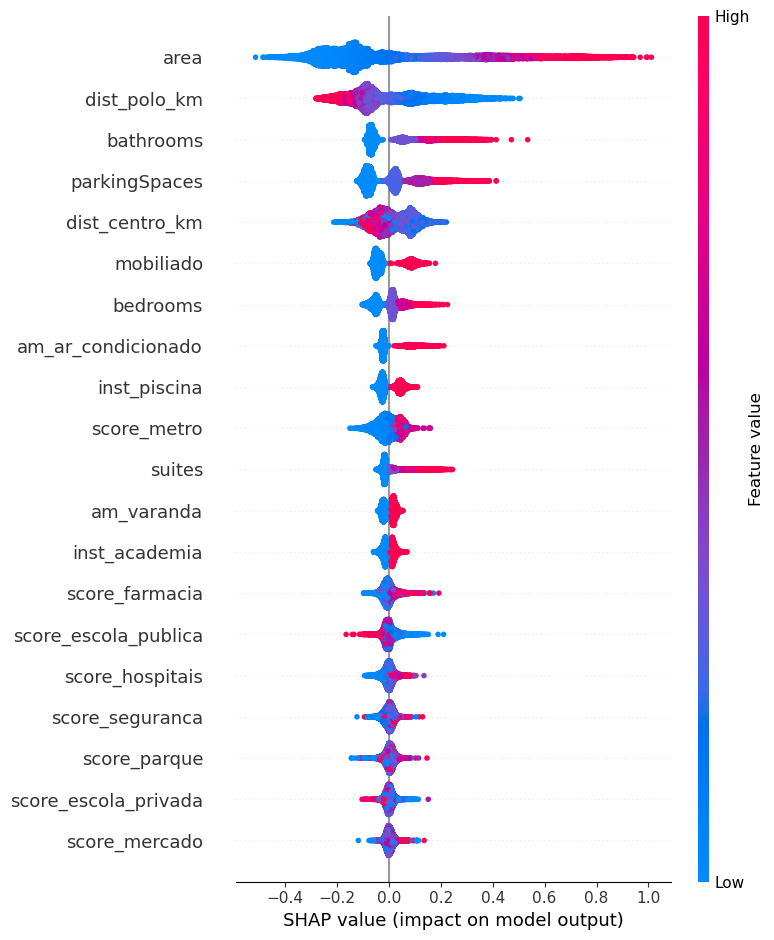

In [65]:
shap.summary_plot(shap_values, X_train_transformed, feature_names=feature_names)

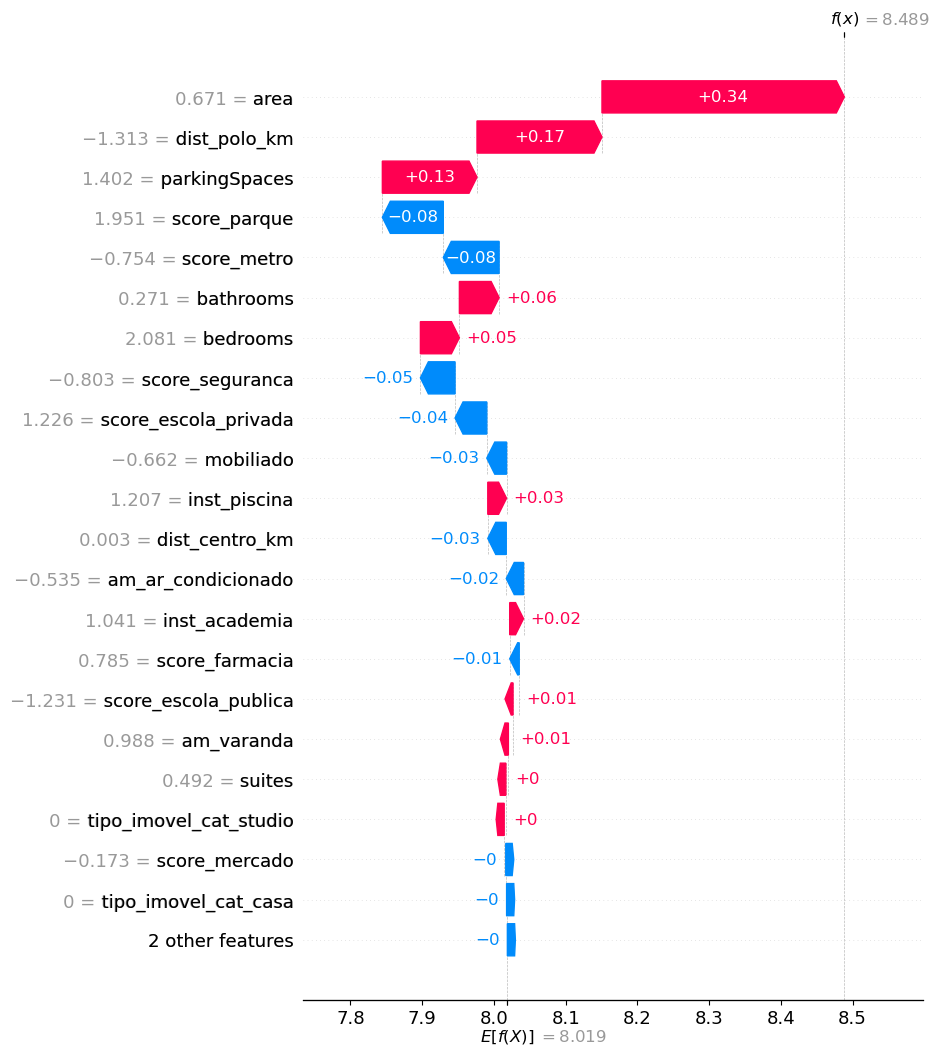

In [68]:
shap.plots.waterfall(
    shap_values[22],
    max_display=22
)

## 💾 Salvando o modelo (pickle)

In [ ]:
import pickle

with open("/home/felipe/Projeto/Portfolio/Portfolio2/Regression_PriceHouse/results/models/aluguel_xgb_price_model.pkl", "wb") as f:
    pickle.dump(final_pipeline, f)

In [ ]:
with open("/home/felipe/Projeto/Portfolio/Portfolio2/Regression_PriceHouse/results/models/aluguel_xgb_price_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

In [ ]:
loaded_model.predict(X_test.iloc[:5])